# Лабораторная работа №2
## Логистическая и линейная регрессия

В этой работе я использую те же данные, что и в первой лабораторной,
но вместо KNN обучаю логистическую и линейную регрессию.
Проверю, какие преобразования помогают этим моделям, затем реализую оба алгоритма
на NumPy и сравню результаты со sklearn.

| Задача | Модель | Целевая переменная | Основная метрика |
|:--|:--|:--|:--|
| Одобрение кредитной заявки | Логистическая регрессия | `loan_status` | F1 ↑ |
| Прочность бетона | Линейная регрессия | `strength`, МПа | MAE ↓ |

Сохраняю разбиения первой работы: **36 000 / 9 000** заявок и **799 / 206** измерений бетона.
Это позволит сравнить новые модели с KNN на тех же объектах.
Описание данных, метрик и всех преобразований приведено ниже.

**Ход работы:** подготовка → исходные модели → гипотезы улучшения → своя реализация → выводы.

---

### Почему выбраны эти задачи

**Классификация.** По сведениям о клиенте и запрошенном кредите предсказываю историческое
одобрение заявки: `loan_status=1` — одобрено, `0` — отказ.
Такая задача подходит для предварительной оценки заявок. Из входов исключаю цель
и `loan_int_rate`, поскольку прогноз нужен до назначения ставки.
Доход, сумма и их отношение считаю известными на момент подачи заявки.
Сочетание числовых и категориальных признаков позволяет проверить подготовку данных
и регуляризацию логистической регрессии. Набор синтетический; одобрение не равно будущему дефолту.

**Регрессия.** По составу смеси и возрасту предсказываю прочность бетона в МПа.
Это помогает предварительно оценивать рецептуры и планировать испытания.
Связь прочности с возрастом и составом может быть нелинейной, поэтому интересно проверить,
насколько помогут линейной модели log-признаки и полиномы.
Цель `strength` не входит в признаки и не преобразуется.

### Какие признаки используются

В кредитном наборе 45 000 строк и 14 столбцов. После исключения цели и ставки остаётся
12 входных признаков: 7 числовых и 5 категориальных.

| Признак | Смысл |
|:--|:--|
| `person_age` | Возраст клиента, годы |
| `person_gender` | Пол |
| `person_education` | Уровень образования |
| `person_income` | Годовой доход |
| `person_emp_exp` | Стаж работы, годы |
| `person_home_ownership` | Тип владения жильём |
| `loan_amnt` | Запрашиваемая сумма кредита |
| `loan_intent` | Цель кредита |
| `loan_percent_income` | Отношение суммы кредита к доходу |
| `cb_person_cred_hist_length` | Длительность кредитной истории, годы |
| `credit_score` | Кредитный рейтинг |
| `previous_loan_defaults_on_file` | Наличие прошлых дефолтов |
| `loan_int_rate` | Процентная ставка; исключаю из входов |
| `loan_status` | Цель: 1 — одобрено, 0 — отказ |

Единицы дохода и суммы кредита в доступном описании отдельно не уточняются,
поэтому трактую их как денежные величины в одной шкале.

В наборе бетона 1030 строк, 8 входных признаков и одна целевая переменная.

| Признак | Смысл | Единицы |
|:--|:--|:--|
| `cement` | Цемент | кг/м³ |
| `slag` | Доменный шлак | кг/м³ |
| `fly_ash` | Зола-унос | кг/м³ |
| `water` | Вода | кг/м³ |
| `superplasticizer` | Суперпластификатор | кг/м³ |
| `coarse_aggregate` | Крупный заполнитель | кг/м³ |
| `fine_aggregate` | Мелкий заполнитель | кг/м³ |
| `age` | Возраст образца | дни |
| `strength` | Цель: прочность при сжатии | МПа |

Оба исходных набора не содержат пропусков. Заполнение пропусков всё равно включаю
в Pipeline как часть подготовки. После удаления 25 полных дубликатов бетона
остаётся 1005 измерений: **799 строк и 342 рецептуры в train**, **206 строк и 86 рецептур в test**.
Кредитный набор не содержит полных дубликатов; train/test — **36 000 / 9 000** строк.


### Как понимать метрики

Основные показатели считаю по формулам:

$$F_1=\frac{2TP}{2TP+FP+FN},\qquad
  MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.$$

Здесь TP — правильно предсказанные одобрения, FP — ошибочные одобрения,
FN — пропущенные одобрения. В кредитных данных класс 1 составляет около 22,2%,
поэтому одной accuracy недостаточно. F1 помогает одновременно учитывать точность и полноту,
а MAE показывает ошибку прочности в понятных единицах — МПа.

| Дополнительная метрика | Что показывает |
|:--|:--|
| Precision | Какая доля предсказанных одобрений действительно относится к классу 1 |
| Recall | Какая доля реальных одобрений найдена моделью |
| Accuracy | Доля правильных ответов среди всех заявок |
| Balanced accuracy | Средняя полнота по двум классам, с одинаковым вкладом каждого класса |
| ROC-AUC | Насколько хорошо вероятности ранжируют классы при разных порогах; случайный ориентир — 0,5 |
| Average precision (AP) | Качество ранжирования через precision и recall; ориентир случайного ранжирования — доля класса 1 |
| RMSE | Корень средней квадратичной ошибки в МПа; сильнее реагирует на крупные промахи |
| R² | $1-\sum(y_i-\hat y_i)^2/\sum(y_i-\bar y)^2$; сравнение с постоянным прогнозом среднего, может быть отрицательным |

В сравнении разных алгоритмов для одной задачи использую один и тот же набор метрик.
F1 и ошибки прочности между собой не складываю: они относятся к разным задачам.


### Источники и выбор данных

Автор кредитного набора — **taweilo**,
[страница Loan Approval на Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data).
В работе использую CSV из [публичной копии с фиксированным commit](https://github.com/dpidaparthi/loan-approval-classification/blob/379a24f61cd5d9f032415b14a5797f30cf1d4a05/data/loan_data.csv).
Побайтовое совпадение с загрузкой Kaggle не проверено: контрольная сумма в коде относится
к этой копии. По описанию автора набор синтетический, с расширением SMOTENC.
Условия использования задаются источником Kaggle; отдельную лицензию на данные я не назначаю.

Набор бетона: **Yeh, I. (1998), Concrete Compressive Strength**,
[UCI №165, DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67).
Использую исходный XLS из [официального архива UCI](https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip),
лицензия — [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

При подготовке первой работы выбор сверялся с
[таблицей группы](https://docs.google.com/spreadsheets/d/1szg1vYr3MLq8eqCejGbvVOdF7t87slb3h2x8qv2e-So/edit?gid=0)
**10 ноября 2026 года**. В сохранённой проверке учтено 20 записей,
совпадений выбранных наборов с другими студентами не найдено.
Это результат сверки на указанную дату, а не повторная проверка текущего состояния таблицы.

## 1. Подготовка данных
### Библиотеки и настройки

Подключу библиотеки и функции чтения данных из первой работы.
Как и раньше, ограничу число потоков для более сопоставимых измерений времени.

In [1]:
# Настройки окружения задаются до импорта NumPy для воспроизводимых измерений времени.
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/vkr_matplotlib")
import sys
import json
import platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
ROOT = Path.cwd() if (Path.cwd() / "lab_1").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "lab_2" / "results"
RESULTS.mkdir(exist_ok=True)
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid")
print({"python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

# Общий стиль таблиц и графиков.
MODEL_NAMES = {
    "sklearn_baseline": "sklearn · исходная",
    "sklearn_improved": "sklearn · улучшенная",
    "custom_baseline": "своя · исходная",
    "custom_improved": "своя · улучшенная",
    "dummy": "Dummy",
}
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
COLUMN_NAMES = {
    "model": "Модель", "task": "Задача", "lab": "Работа", "dataset": "Набор данных",
    "algorithm": "Алгоритм", "implementation": "Реализация", "stage": "Вариант",
    "f1": "F1 ↑", "precision": "Precision", "recall": "Recall",
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "ROC-AUC", "average_precision": "AP", "mae": "MAE, МПа ↓",
    "rmse": "RMSE, МПа ↓", "r2": "R² ↑", "fit_seconds": "Обучение, с",
    "predict_seconds": "Прогноз, с", "mode": "Признаки", "representation": "Признаки",
    "cv_mean": "Среднее CV", "cv_std": "Разброс CV", "mean_test_score": "Среднее CV",
    "std_test_score": "Разброс CV", "rank_test_score": "Место", "status": "Статус",
    "comparison": "Сравнение", "delta": "Изменение", "metric": "Метрика",
    "estimator": "Алгоритм", "n_iter": "Итерации", "gradient_norm": "Норма градиента",
    "objective": "Функция потерь", "missing_train": "Пропуски", "dtype": "Тип",
    "missing": "Пропуски", "unique": "Уникальные", "type": "Тип",
    "param_model__n_neighbors": "Соседи (k)", "param_model__weights": "Веса",
    "param_model__p": "Расстояние (p)", "class_weight": "Веса классов",
    "count": "Количество", "fraction": "Доля", "train_fraction": "Доля в train",
}

def show_table(value, title=None):
    """Вывод таблицы с подписями и одинаковой точностью чисел."""
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if not isinstance(value, pd.DataFrame):
        display(value)
        return
    table = value.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda item: MODEL_NAMES.get(item, TASK_NAMES.get(item, item)) if isinstance(item, str) else item)
    table = table.rename(columns=COLUMN_NAMES)
    styled = table.style.format(precision=4, na_rep="—").set_table_styles([
        {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#243b53"),
                                     ("padding", "9px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e8edf2")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                          ("font-weight", "600"), ("padding", "10px 0")]},
    ])
    if isinstance(table.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if title:
        styled = styled.set_caption(title)
    if "Норма градиента" in table.columns:
        styled = styled.format({"Норма градиента": "{:.2e}"})
    display(styled)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=["#387ca3", "#db9655", "#4c9c8a", "#9c7cb5"]),
})

{'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Чтение данных и восстановление разбиений

Приведу код проверки файлов, расчёта метрик, создания признаков и чтения сохранённых
train/test. Контрольные суммы и проверки групп гарантируют, что сравнение с KNN
проводится на тех же наблюдениях.

In [2]:
# Общие функции данных и метрик.
"""Два датасета, общий протокол, признаки и метрики лабораторной №1."""

import hashlib

from pathlib import Path

import warnings

import numpy as np

import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, mean_absolute_error,
                             root_mean_squared_error, r2_score)

SEED = 42

CATEGORICAL = ["person_gender", "person_education", "person_home_ownership",
               "loan_intent", "previous_loan_defaults_on_file"]

CONCRETE_COLUMNS = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                    "coarse_aggregate", "fine_aggregate", "age", "strength"]

DATASETS = {
    "classification": {
        "name": "Loan Approval Classification Data", "file": "loan_data.csv",
        "sha256": "67cca604cd71cbd605014f721d078d20d44d726d625945591450733535f9868a",
        "target": "loan_status", "excluded": ["loan_status", "loan_int_rate"],
        "protocol_id": "loan-v1-seed42-test20", "expected_shape": (45000, 14),
    },
    "regression": {
        "name": "Concrete Compressive Strength", "file": "Concrete_Data.xls",
        "sha256": "710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4",
        "target": "strength", "excluded": ["strength"],
        "protocol_id": "concrete-v1-recipe-groups-seed42-test20", "expected_shape": (1030, 9),
    },
}

EXCLUDED = {task: spec["excluded"] for task, spec in DATASETS.items()}

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def load_dataset(lab, task):
    """Чтение исходного файла с проверкой SHA256; y не меняется."""
    spec = DATASETS[task]
    path = Path(lab) / "data" / "raw" / spec["file"]
    if sha256(path) != spec["sha256"]:
        raise ValueError(f"Контрольная сумма {path.name} не совпала")
    if task == "classification":
        frame = pd.read_csv(path)
    else:
        # Подавляем только сообщение о будущем удалении xlrd из pandas, не ошибки данных.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="The xlrd engine is deprecated.*")
            frame = pd.read_excel(path, engine="xlrd")
        frame.columns = CONCRETE_COLUMNS
    if frame.shape != spec["expected_shape"]:
        raise ValueError(f"Неожиданная форма {path.name}: {frame.shape}")
    return frame

class TaskFeatures(TransformerMixin, BaseEstimator):
    """Детерминированные признаки: не используют y и статистики test."""
    def __init__(self, task="classification", mode="raw"):
        self.task = task
        self.mode = mode

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        if self.mode in ("log", "engineered"):
            column = "person_income" if self.task == "classification" else "age"
            result[column] = np.log1p(result[column].clip(lower=0))
        if self.mode == "engineered":
            if self.task == "classification":
                result["employment_age_ratio"] = X["person_emp_exp"] / X["person_age"].clip(lower=1)
                result["credit_history_age_ratio"] = X["cb_person_cred_hist_length"] / X["person_age"].clip(lower=1)
            else:
                binder = (X["cement"] + X["slag"] + X["fly_ash"]).clip(lower=1e-12)
                result["binder"] = binder
                result["water_binder_ratio"] = X["water"] / binder
                result["aggregate_binder_ratio"] = (X["coarse_aggregate"] + X["fine_aggregate"]) / binder
        return result

def evaluate(task, truth, prediction, probabilities=None):
    if task == "classification":
        return {
            "f1": f1_score(truth, prediction, zero_division=0),
            "precision": precision_score(truth, prediction, zero_division=0),
            "recall": recall_score(truth, prediction, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(truth, prediction),
            "accuracy": accuracy_score(truth, prediction),
            "roc_auc": roc_auc_score(truth, probabilities),
            "average_precision": average_precision_score(truth, probabilities),
        }
    return {"mae": mean_absolute_error(truth, prediction),
            "rmse": root_mean_squared_error(truth, prediction),
            "r2": r2_score(truth, prediction)}

# Восстановление тех же выборок и фолдов.
"""Общий протокол с лабораторной №1 и Pipeline линейных моделей."""

import json

import numpy as np

import pandas as pd

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge

from sklearn.model_selection import GroupKFold, StratifiedKFold

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

def load_tasks(root):
    """Читаем сохранённые разбиения №1, проверяя SHA, полноту и группы."""
    lab = root / "lab_1"
    protocol = json.loads((lab / "results" / "protocol.json").read_text())
    tasks = {}
    for task, spec in DATASETS.items():
        raw = load_dataset(lab, task)
        data = raw.drop_duplicates()
        path = lab / "results" / f"split_{task}.csv"
        reference = protocol["datasets"][task]
        if sha256(path) != reference["split_sha"]:
            raise ValueError(f"Изменилось разбиение {task}")
        split = pd.read_csv(path)
        assert not split.row_id.duplicated().any()
        assert set(split.row_id) == set(data.index)
        assert set(split.split) == {"train", "test"}
        train = split.loc[split.split == "train", "row_id"].to_numpy()
        test = split.loc[split.split == "test", "row_id"].to_numpy()
        X, y = data.drop(columns=spec["excluded"]), data[spec["target"]]
        assert list(X.columns) == reference["features"]
        if task == "regression":
            groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X.drop(columns="age")))[0], index=X.index)
        else:
            groups = pd.Series(X.index, index=X.index)
        np.testing.assert_array_equal(groups.loc[split.row_id], split.group_id)
        assert set(groups.loc[train]).isdisjoint(groups.loc[test])
        if task == "classification":
            folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(X.loc[train], y.loc[train]))
        else:
            folds = list(GroupKFold(3).split(X.loc[train], y.loc[train], groups.loc[train]))
        for a, b in folds:
            assert set(groups.loc[train].iloc[a]).isdisjoint(groups.loc[train].iloc[b])
        tasks[task] = dict(X_train=X.loc[train], X_test=X.loc[test],
                           y_train=y.loc[train], y_test=y.loc[test], cv=folds,
                           split=split, spec=spec, split_sha=sha256(path),
                           duplicates_removed=len(raw) - len(data))
    return tasks

### Обучающая и тестовая выборки

Возьму сохранённые разбиения, проверю контрольные суммы и порядок строк.
Для классификации использую три стратифицированных фолда, для бетона — три групповых фолда
по рецептурам. Одинаковые смеси не должны пересекаться между обучением и проверкой.

Основными метриками оставляю F1 класса 1 и MAE в МПа. Дополнительно считаю precision,
recall, accuracy, balanced accuracy, ROC-AUC, AP, а для регрессии — RMSE и R².

### Условия эксперимента

| Параметр | Классификация | Регрессия |
|:--|:--|:--|
| Train / test | 36 000 / 9 000 заявок | 799 / 206 измерений |
| Разбиение | 80/20, со стратификацией | 80/20 по рецептурам, GroupShuffleSplit |
| Кросс-валидация | StratifiedKFold(3), shuffle=True | GroupKFold(3) по рецептурам |
| Случайное состояние | 42 | 42 |
| Выбор параметров | Максимум среднего F1 на train-CV | Минимум средней MAE на train-CV |

Рецептура — совпадение количеств всех семи компонентов смеси; возраст и прочность
не входят в ключ группы. Поэтому одна смесь в разных возрастах не пересекает train/test
и обучающие/валидационные части CV. Доля строк test для бетона составляет около 20,5%,
поскольку разделяются группы, а не отдельные измерения.

Все оценки CV считаю на полном train. Заполнение пропусков, кодирование и масштабирование
обучаются внутри каждого фолда. EDA использует только train. После выбора настроек
переобучаю модель на полном train и один раз оцениваю каждый зафиксированный вариант на test.
По результатам test параметры не меняю. Повторный поиск на одних CV-фолдах может завышать
оценку победившей конфигурации, поэтому отдельно показываю и CV, и test.


In [3]:
# load_tasks восстанавливает порядок train/test из CSV первой работы и проверяет группы.
tasks = load_tasks(ROOT)
fold_records = []
for task, t in tasks.items():
    t["split"].to_csv(RESULTS / f"split_{task}.csv", index=False)
    for fold, (train_fold, valid_fold) in enumerate(t["cv"]):
        for subset, positions in [("train", train_fold), ("validation", valid_fold)]:
            fold_records.extend({"task": task, "fold": fold, "subset": subset, "row_id": int(row)}
                                for row in t["X_train"].index[positions])
    print(f"{TASK_NAMES[task]}: train — {len(t['X_train'])}, test — {len(t['X_test'])}.")
    show_table(pd.DataFrame({"dtype": t["X_train"].dtypes.astype(str),
                          "missing_train": t["X_train"].isna().sum()}))
pd.DataFrame(fold_records).to_csv(RESULTS / "cv_folds.csv", index=False)
scoring = {"classification": "f1", "regression": "neg_mean_absolute_error"}

Классификация: train — 36000, test — 9000.


,Тип,Пропуски
person_age,float64,0
person_gender,str,0
person_education,str,0
person_income,float64,0
person_emp_exp,int64,0
person_home_ownership,str,0
loan_amnt,float64,0
loan_intent,str,0
loan_percent_income,float64,0
cb_person_cred_hist_length,float64,0


Регрессия: train — 799, test — 206.


,Тип,Пропуски
cement,float64,0
slag,float64,0
fly_ash,float64,0
water,float64,0
superplasticizer,float64,0
coarse_aggregate,float64,0
fine_aggregate,float64,0
age,int64,0


### Посмотрим на распределения

Проверю соотношение классов, распределение дохода и связь возраста бетона с прочностью.
Это поможет объяснить, зачем пробовать логарифмирование и нелинейные признаки.
Для графиков использую только train. Необычные значения возраста и стажа
сохраняю, как в первой работе.

,Количество,Доля
loan_status,,
0,28000,0.7778
1,8000,0.2222


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
count,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000
mean,277.6300,70.2200,55.9300,182.5500,5.8200,974.0500,772.9600,47.5800,34.9700
std,102.5000,87.4000,63.9700,21.4300,5.7100,73.8100,83.1400,67.0100,15.8100
min,108.3000,0.0000,0.0000,121.7500,0.0000,801.0000,594.0000,1.0000,2.3300
25%,192.0000,0.0000,0.0000,166.6100,0.0000,932.0000,716.9500,14.0000,23.6600
50%,266.0000,15.0000,0.0000,185.7000,6.0000,968.0000,780.5800,28.0000,33.7200
75%,339.0000,137.1000,117.5400,193.0000,9.9000,1025.0000,829.7500,56.0000,44.4700
max,540.0000,359.4000,200.1000,246.9000,32.2000,1125.0000,992.6000,365.0000,80.2000


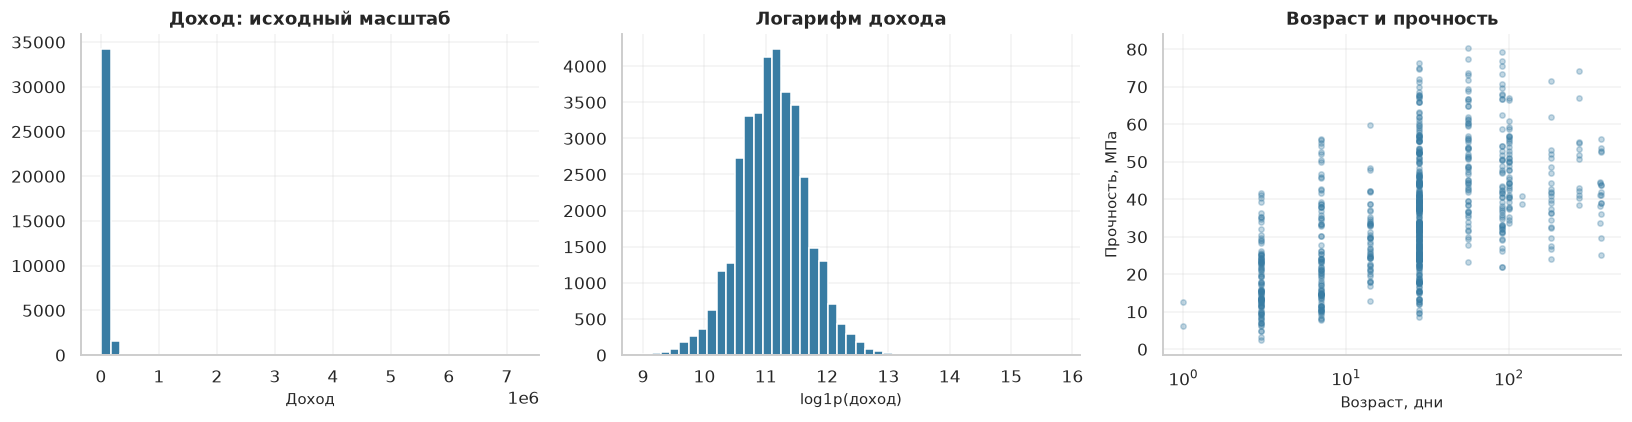

In [4]:
# EDA не обращается к отложенной выборке; справочные распределения строятся только на train.
c, r = tasks["classification"], tasks["regression"]
show_table(c["y_train"].value_counts().rename("count").to_frame().assign(
    fraction=c["y_train"].value_counts(normalize=True)))
show_table(r["X_train"].join(r["y_train"]).describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(c["X_train"]["person_income"], bins=45)
axes[0].set(title="Доход: исходный масштаб", xlabel="Доход")
axes[1].hist(np.log1p(c["X_train"]["person_income"].clip(lower=0)), bins=45)
axes[1].set(title="Логарифм дохода", xlabel="log1p(доход)")
axes[2].scatter(r["X_train"]["age"], r["y_train"], s=12, alpha=.3)
axes[2].set(xscale="log", xlabel="Возраст, дни", ylabel="Прочность, МПа", title="Возраст и прочность")
plt.tight_layout()
plt.show()

### Наблюдения по данным

Класс одобрения составляет около 22,2% заявок, поэтому классы заметно несбалансированы. У дохода выражен правый хвост: большинство значений находятся внизу диапазона, а отдельные большие доходы растягивают шкалу. Это объясняет выбор F1 и гипотезу с log1p.

Для бетона прочность зависит не только от состава, но и от возраста образца. На графике с логарифмической шкалой возраста эту связь удобнее рассматривать. Поэтому далее отдельно проверю log1p возраста и дополнительные признаки состава.

## 2. Исходные модели

Для классификации возьму **LogisticRegression с C=1**, L2-регуляризацией
и обычными весами классов. Класс 1 буду выбирать при вероятности выше 0,5.
Обучение выполняю методом `newton-cholesky`, с точностью `1e-9`
и ограничением в 100 итераций.

Для регрессии начну с **LinearRegression**, то есть обычного метода наименьших квадратов.

Числовые признаки стандартизирую после заполнения пропусков медианой.
Для категорий использую заполнение модой и one-hot с `drop='first'`, чтобы избежать
зависимости полного набора индикаторов и свободного члена.
Все преобразования выполняются внутри Pipeline на каждом CV-фолде.

Сначала посчитаю CV-оценки. Качество всех вариантов на test сравню после выбора параметров.
Dummy оставлю как простой ориентир из первой работы.

### Pipeline линейных моделей

Ниже объединю преобразования и модель. В варианте `polynomial` сначала создаю
log-признаки и отношения, стандартизирую их, добавляю все квадраты и попарные
взаимодействия числовых признаков и стандартизирую результат ещё раз.
One-hot категории в полиномы не включаю.

In [5]:
# Создание sklearn-моделей и полного Pipeline.
def sklearn_model(task, **params):
    if task == "classification":
        return LogisticRegression(solver="newton-cholesky", max_iter=100, tol=1e-9, **params)
    alpha = params.pop("alpha", 0.0)
    return LinearRegression(**params) if alpha == 0 else Ridge(alpha=alpha, solver="svd", **params)

def make_pipeline(X, task, mode="scaled", estimator=None):
    if mode not in ("scaled", "log", "engineered", "polynomial"):
        raise ValueError(f"Неизвестное представление {mode}")
    categorical = [column for column in CATEGORICAL if column in X]
    numeric = [column for column in X if column not in categorical]
    feature_mode = "engineered" if mode == "polynomial" else mode
    if feature_mode == "engineered":
        numeric += (["employment_age_ratio", "credit_history_age_ratio"] if task == "classification"
                    else ["binder", "water_binder_ratio", "aggregate_binder_ratio"])
    steps = [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    if mode == "polynomial":
        steps += [("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
                  ("rescale", StandardScaler())]
    transforms = [("numeric", Pipeline(steps), numeric)]
    if categorical:
        transforms.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ("features", TaskFeatures(task, feature_mode)),
        ("preprocess", ColumnTransformer(transforms, sparse_threshold=0)),
        ("model", sklearn_model(task) if estimator is None else estimator),
    ])

### Оценка исходных моделей по кросс-валидации

Теперь применю подготовленный Pipeline к трём фолдам train и посчитаю среднее качество исходной модели.

In [6]:
# Бейзлайны задаются до проверки гипотез; CV использует весь train, без подвыборок.
base_models, hypothesis_records = {}, []
for task, t in tasks.items():
    base_models[task] = make_pipeline(t["X_train"], task, "scaled")
    scores = cross_val_score(base_models[task], t["X_train"], t["y_train"],
                             cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
    hypothesis_records.append(dict(task=task, mode="scaled", cv_mean=float(scores.mean()),
                                   cv_std=float(scores.std()), folds=scores.tolist()))
    print(task, "исходный CV-score:", scores, flush=True)

classification исходный CV-score: [0.6779932  0.69665605 0.68666667]


regression исходный CV-score: [-8.49562775 -8.09971508 -7.9376989 ]


## 3. Проверка гипотез

Попробую следующие изменения:

| Гипотеза | Изменение | Ожидаемый эффект |
|:--|:--|:--|
| H1 · `log` | log1p дохода или возраста бетона | Лучше описать асимметрию дохода и рост прочности с возрастом |
| H2 · `engineered` | Отношения признаков из первой работы | Добавить полезные зависимости между величинами |
| H3 · `polynomial` | Квадраты и взаимодействия числовых признаков | Описать нелинейные связи с помощью линейной модели |
| H4 · регуляризация | Подбор C, весов классов и alpha | Снизить переобучение и улучшить итоговое качество |

В `engineered` для кредитов добавляю стаж/возраст и кредитную историю/возраст,
а для бетона — массу вяжущего, воду/вяжущее и заполнители/вяжущее.
В `polynomial` расширяю эти числовые признаки до второй степени и снова стандартизирую.
Категории в полиномы не включаю, целевую переменную не преобразую.

Сначала сравню представления при исходных параметрах. Затем подберу их совместно
с регуляризацией, поскольку сложные признаки могут начать работать лучше именно с ней.

- Классификация: C ∈ {0.01, 0.1, 1, 10}, веса классов — обычные или `balanced`.
- Регрессия: МНК или Ridge с alpha ∈ {0.01, 0.1, 1, 10, 100}.

Получается 32 конфигурации для классификации и 24 для регрессии.
Выбираю по среднему F1 или отрицательной MAE на тех же трёх фолдах train.
Test и порог 0,5 при подборе не меняю.

In [7]:
# Изолируем эффект представления, сохраняя исходные параметры моделей.
for task, t in tasks.items():
    for mode in ["log", "engineered", "polynomial"]:
        scores = cross_val_score(make_pipeline(t["X_train"], task, mode),
                                 t["X_train"], t["y_train"], cv=t["cv"],
                                 scoring=scoring[task], n_jobs=1, error_score="raise")
        hypothesis_records.append(dict(task=task, mode=mode, cv_mean=float(scores.mean()),
                                       cv_std=float(scores.std()), folds=scores.tolist()))
        print(task, mode, "CV mean:", scores.mean(), flush=True)
hypotheses = pd.DataFrame(hypothesis_records)
hypotheses.to_json(RESULTS / "hypotheses.json", orient="records", indent=2)
show_table(hypotheses.drop(columns="folds").round(6))

classification log CV mean: 0.7052708976989822


classification engineered CV mean: 0.7040779416149027


classification polynomial CV mean: 0.7082557389162351


regression log CV mean: -5.577415475543449


regression engineered CV mean: -5.580760650107148


regression polynomial CV mean: -5.185470876705199


Задача,Признаки,Среднее CV,Разброс CV
Классификация,scaled,0.6871,0.0076
Регрессия,scaled,-8.1777,0.2344
Классификация,log,0.7053,0.0058
Классификация,engineered,0.7041,0.0059
Классификация,polynomial,0.7083,0.0053
Регрессия,log,-5.5774,0.1804
Регрессия,engineered,-5.5808,0.2368
Регрессия,polynomial,-5.1855,0.6522


### Подбор параметров

Запущу GridSearchCV по всем указанным комбинациям.
Ниже выведу лучшие варианты, среднее качество и разброс по фолдам.
Полные результаты сохраню, чтобы при необходимости посмотреть и остальные настройки.

In [8]:
# GridSearchCV получает список готовых Pipeline и не использует test для выбора.
searches, selected = {}, {}
modes = ["scaled", "log", "engineered", "polynomial"]
for task, t in tasks.items():
    grid = []
    for mode in modes:
        pipe = make_pipeline(t["X_train"], task, mode)
        if task == "classification":
            grid.append({"features": [pipe.named_steps["features"]],
                         "preprocess": [pipe.named_steps["preprocess"]],
                         "model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]})
        else:
            common = {"features": [pipe.named_steps["features"]],
                      "preprocess": [pipe.named_steps["preprocess"]]}
            grid.append({**common, "model": [LinearRegression()]})
            grid.append({**common, "model": [Ridge(solver="svd")], "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]})
    search = GridSearchCV(base_models[task], grid, cv=t["cv"], scoring=scoring[task],
                          n_jobs=1, error_score="raise", refit=True)
    search.fit(t["X_train"], t["y_train"])
    searches[task] = search
    best = search.best_estimator_
    feature_mode = best.named_steps["features"].mode
    numeric_steps = best.named_steps["preprocess"].named_transformers_["numeric"].named_steps
    mode = "polynomial" if "polynomial" in numeric_steps else feature_mode
    model = best.named_steps["model"]
    params = ({"C": float(model.C), "class_weight": model.class_weight} if task == "classification"
              else {"alpha": float(getattr(model, "alpha", 0.0))})
    selected[task] = {"mode": mode, "params": params, "estimator": type(model).__name__,
                      "cv_score": float(search.best_score_)}
    cv_rows = []
    for index, config in enumerate(search.cv_results_["params"]):
        config_mode = config["features"].mode
        if "polynomial" in config["preprocess"].transformers[0][1].named_steps:
            config_mode = "polynomial"
        cv_rows.append({"mode": config_mode,
                        "C": config.get("model__C"), "class_weight": config.get("model__class_weight"),
                        "alpha": config.get("model__alpha", 0.0) if task == "regression" else None,
                        **{key: search.cv_results_[key][index] for key in
                           ["mean_test_score", "std_test_score", "rank_test_score",
                            "split0_test_score", "split1_test_score", "split2_test_score"]}})
    cv_table = pd.DataFrame(cv_rows)
    cv_table.to_csv(RESULTS / f"cv_{task}.csv", index=False)
    show_table(cv_table.sort_values("rank_test_score").head(8))
(RESULTS / "selected.json").write_text(json.dumps(selected, ensure_ascii=False, indent=2));
# Явно покажу лучший набор признаков и параметры каждой модели.
for task, config in selected.items():
    params = config["params"]
    row = {"Задача": TASK_NAMES[task], "Алгоритм": config["estimator"], "Признаки": config["mode"]}
    if task == "classification":
        row.update({"C": params["C"], "Веса классов": "Обычные" if params["class_weight"] is None else params["class_weight"],
                    "Порог": 0.5, "Средний F1 по CV": config["cv_score"]})
    else:
        row.update({"alpha": params["alpha"], "Средняя MAE по CV, МПа": -config["cv_score"]})
    show_table(pd.DataFrame([row]), "Выбранная конфигурация")


,Признаки,C,Веса классов,alpha,Среднее CV,Разброс CV,Место,split0_test_score,split1_test_score,split2_test_score
26,polynomial,0.1000,—,—,0.7084,0.0032,1,0.7040,0.7112,0.7101
28,polynomial,1.0000,—,—,0.7083,0.0053,2,0.7008,0.7128,0.7112
30,polynomial,10.0000,—,—,0.7082,0.0064,3,0.6993,0.7140,0.7114
14,log,10.0000,—,—,0.7056,0.0054,4,0.6983,0.7114,0.7070
12,log,1.0000,—,—,0.7053,0.0058,5,0.6975,0.7114,0.7069
22,engineered,10.0000,—,—,0.7041,0.0061,6,0.6973,0.7121,0.7029
20,engineered,1.0000,—,—,0.7041,0.0059,7,0.6974,0.7118,0.7030
18,engineered,0.1000,—,—,0.7035,0.0061,8,0.6963,0.7112,0.7030


,Признаки,C,Веса классов,alpha,Среднее CV,Разброс CV,Место,split0_test_score,split1_test_score,split2_test_score
21,polynomial,—,—,1.0000,-4.8906,0.1698,1,-4.8161,-5.1255,-4.7301
22,polynomial,—,—,10.0000,-4.8930,0.2232,2,-4.8242,-5.1942,-4.6605
20,polynomial,—,—,0.1000,-4.9261,0.2260,3,-4.8059,-5.2428,-4.7297
19,polynomial,—,—,0.0100,-5.0352,0.4253,4,-4.8125,-5.6303,-4.6626
18,polynomial,—,—,0.0000,-5.1855,0.6522,5,-4.8105,-6.1028,-4.6431
23,polynomial,—,—,100.0000,-5.2647,0.3979,6,-5.4902,-5.5983,-4.7055
16,engineered,—,—,10.0000,-5.5441,0.2091,7,-5.7953,-5.5537,-5.2834
15,engineered,—,—,1.0000,-5.5676,0.2202,8,-5.8462,-5.5491,-5.3076


Задача,Алгоритм,Признаки,C,Веса классов,Порог,Средний F1 по CV
Классификация,LogisticRegression,polynomial,0.1000,Обычные,0.5000,0.7084


Задача,Алгоритм,Признаки,alpha,"Средняя MAE по CV, МПа"
Регрессия,Ridge,polynomial,1.0000,4.8906


### Какие гипотезы сработали

Сравню средние CV-оценки после каждого изменения.
Положительная разность означает рост F1 или снижение MAE.
Очень маленький выигрыш по сравнению с разбросом фолдов
буду считать слабым основанием для вывода.

In [9]:
# Сравню каждое представление с предыдущим, а поиск параметров — с лучшим исходным.
hypothesis_rows = []
for task in tasks:
    h = hypotheses[hypotheses.task == task].set_index("mode")
    for name, new, old in [("H1 · логарифмирование", "log", "scaled"),
                           ("H2 · новые признаки", "engineered", "log"),
                           ("H3 · полиномы", "polynomial", "engineered")]:
        delta = h.loc[new, "cv_mean"] - h.loc[old, "cv_mean"]
        hypothesis_rows.append({"Задача": TASK_NAMES[task], "Гипотеза": name,
                                "Изменение CV-score": delta,
                                "Результат": "Лучше по среднему CV" if delta > 0 else "Улучшения нет"})
    gain = selected[task]["cv_score"] - h.cv_mean.max()
    hypothesis_rows.append({"Задача": TASK_NAMES[task], "Гипотеза": "H4 · подбор параметров",
                            "Изменение CV-score": gain,
                            "Результат": "Лучше по среднему CV" if gain > 0 else "Улучшения нет"})
show_table(pd.DataFrame(hypothesis_rows), "Результаты проверки гипотез")

Задача,Гипотеза,Изменение CV-score,Результат
Классификация,H1 · логарифмирование,0.0182,Лучше по среднему CV
Классификация,H2 · новые признаки,-0.0012,Улучшения нет
Классификация,H3 · полиномы,0.0042,Лучше по среднему CV
Классификация,H4 · подбор параметров,0.0002,Лучше по среднему CV
Регрессия,H1 · логарифмирование,2.6003,Лучше по среднему CV
Регрессия,H2 · новые признаки,-0.0033,Улучшения нет
Регрессия,H3 · полиномы,0.3953,Лучше по среднему CV
Регрессия,H4 · подбор параметров,0.2949,Лучше по среднему CV


## 4. Самостоятельная реализация

### Логистическая регрессия
Для двух классов $p=\sigma(Xw+b)$, $\sigma(z)=1/(1+e^{-z})$.
Минимизируем
$$L=\frac{1}{S}\sum_i s_i[\log(1+e^{z_i})-y_i z_i]
+\frac{\|w\|^2}{2CS},\qquad S=\sum_i s_i.$$
Свободный член не штрафую. При `balanced` вес класса равен $n/(2n_c)$,
вычисляется только по обучающим меткам. Эта нормировка соответствует sklearn.

В расширенной матрице $A=[X,1]$ градиент равен
$A^T(s\odot(p-y))/S+D\theta$, гессиан —
$A^T\operatorname{diag}(s\odot p\odot(1-p))A/S+D$;
$D$ содержит $1/(CS)$ для коэффициентов и ноль для свободного члена.
Шаг Ньютона решает $H\Delta=g$, затем $\theta\leftarrow\theta-t\Delta$.
Условие Армихо уменьшает шаг до убывания функции. Остановка: $\|g\|_\infty\le10^{-9}$.
`logaddexp` обеспечивает устойчивую log-loss. При недостижении точности выдаётся предупреждение.

### Линейная регрессия
Минимизируем $\|Xw+b-y\|^2+\alpha\|w\|^2$.
При $\alpha=0$ это МНК. Центрируем $X,y$, решаем задачу через `numpy.linalg.lstsq`
и восстанавливаем $b=\bar y-\bar Xw$. Для Ridge добавляем строки $\sqrt{\alpha}I$ и нулевые цели.
Такой подход не требует обращения $X^TX$ и поддерживает линейно зависимые признаки.

Ниже реализую обучение и прогноз на NumPy. Из sklearn использую интерфейс модели
и проверку входных данных. Те же определения сохраняю в `src/linear_models.py`.

In [10]:
# Определения совпадают с тестируемым модулем; алгоритмы обучения доступны прямо в notebook.
"""Линейные модели: математика и оптимизация реализованы на NumPy."""

import warnings
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_is_fitted, validate_data


def sigmoid(z):
    """Устойчивая сигмоида без переполнения exp на больших |z|."""
    return np.exp(-np.logaddexp(0.0, -np.asarray(z)))


def logistic_loss_gradient_hessian(theta, X, y, C, sample_weight):
    """Средняя взвешенная log-loss + L2; последний столбец X — константа.

    Нормировка совпадает со sklearn: sum(s_i * loss_i) + ||w||²/(2C).
    Здесь всё выражение делится на sum(s_i); свободный член не штрафуется.
    """
    z = X @ theta
    p = sigmoid(z)
    total = sample_weight.sum()
    penalty = np.full(len(theta), 1.0 / (C * total))
    penalty[-1] = 0.0
    loss = (sample_weight @ (np.logaddexp(0.0, z) - y * z)) / total
    loss += 0.5 * np.dot(penalty * theta, theta)
    gradient = X.T @ (sample_weight * (p - y)) / total + penalty * theta
    curvature = sample_weight * p * (1.0 - p) / total
    hessian = X.T @ (curvature[:, None] * X) + np.diag(penalty)
    return float(loss), gradient, hessian


class NumpyLogisticRegression(ClassifierMixin, BaseEstimator):
    """Бинарная логистическая регрессия, L2, метод Ньютона с поиском шага."""

    def __init__(self, C=1.0, class_weight=None, max_iter=100, tol=1e-9):
        self.C = C
        self.class_weight = class_weight
        self.max_iter = max_iter
        self.tol = tol

    def fit(self, X, y):
        if not np.isfinite(self.C) or self.C <= 0:
            raise ValueError("C должен быть положительным конечным числом")
        if self.class_weight not in (None, "balanced"):
            raise ValueError("Поддерживаются class_weight=None и balanced")
        if not isinstance(self.max_iter, (int, np.integer)) or self.max_iter < 1:
            raise ValueError("max_iter должен быть положительным целым")
        if not np.isfinite(self.tol) or self.tol <= 0:
            raise ValueError("tol должен быть положительным конечным числом")
        X, y = validate_data(self, X, y, dtype=np.float64, ensure_2d=True)
        check_classification_targets(y)
        self.classes_, encoded = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("Поддерживаются ровно два класса")
        weight = np.ones(len(y))
        if self.class_weight == "balanced":
            weight = len(y) / (2.0 * np.bincount(encoded)[encoded])
        design = np.column_stack([X, np.ones(len(X))])
        theta = np.zeros(design.shape[1])
        self.loss_history_ = []
        self.converged_ = False
        for iteration in range(self.max_iter):
            loss, gradient, hessian = logistic_loss_gradient_hessian(
                theta, design, encoded, self.C, weight)
            self.loss_history_.append(loss)
            if np.max(np.abs(gradient)) <= self.tol:
                self.converged_ = True
                break
            try:
                direction = np.linalg.solve(hessian, gradient)
            except np.linalg.LinAlgError:
                direction = np.linalg.lstsq(hessian, gradient, rcond=None)[0]
            step = 1.0
            slope = np.dot(gradient, direction)
            # Условие Армихо обеспечивает убывание целевой функции.
            for _ in range(60):
                candidate = theta - step * direction
                z = design @ candidate
                candidate_loss = weight @ (np.logaddexp(0.0, z) - encoded * z) / weight.sum()
                candidate_loss += np.dot(candidate[:-1], candidate[:-1]) / (2 * self.C * weight.sum())
                if candidate_loss <= loss - 1e-4 * step * slope:
                    break
                step *= 0.5
            else:
                break
            theta = candidate
        self.n_iter_ = iteration + 1
        self.coef_ = theta[:-1][None, :]
        self.intercept_ = theta[-1:]
        self.objective_, gradient, _ = logistic_loss_gradient_hessian(
            theta, design, encoded, self.C, weight)
        self.gradient_norm_ = float(np.max(np.abs(gradient)))
        self.converged_ = self.gradient_norm_ <= self.tol
        if not self.converged_:
            warnings.warn("Метод Ньютона не достиг tol", ConvergenceWarning)
        return self

    def decision_function(self, X):
        check_is_fitted(self, ["coef_", "classes_"])
        X = validate_data(self, X, reset=False, dtype=np.float64)
        return (X @ self.coef_.T).ravel() + self.intercept_[0]

    def predict_proba(self, X):
        positive = sigmoid(self.decision_function(X))
        return np.column_stack([1.0 - positive, positive])

    def predict(self, X):
        # При z=0 выбирается первый класс, как в sklearn.
        scores = self.decision_function(X)
        return self.classes_[(scores > 0.0).astype(int)]


class NumpyLinearRegression(RegressorMixin, BaseEstimator):
    """МНК при alpha=0 и Ridge при alpha>0; свободный член без штрафа."""

    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def fit(self, X, y):
        if not np.isfinite(self.alpha) or self.alpha < 0:
            raise ValueError("alpha должен быть конечным неотрицательным числом")
        X, y = validate_data(self, X, y, dtype=np.float64, y_numeric=True)
        if y.ndim != 1:
            raise ValueError("Поддерживается одна целевая переменная")
        x_mean, y_mean = X.mean(axis=0), y.mean()
        centered, target = X - x_mean, y - y_mean
        if self.alpha > 0:
            # Расширенная система реализует ||Xw-y||² + alpha*||w||².
            centered = np.vstack([centered, np.sqrt(self.alpha) * np.eye(X.shape[1])])
            target = np.concatenate([target, np.zeros(X.shape[1])])
        self.coef_, _, self.rank_, self.singular_ = np.linalg.lstsq(centered, target, rcond=None)
        self.intercept_ = float(y_mean - x_mean @ self.coef_)
        return self

    def predict(self, X):
        check_is_fitted(self, ["coef_", "intercept_"])
        X = validate_data(self, X, reset=False, dtype=np.float64)
        return X @ self.coef_ + self.intercept_

### Обучение и сравнение на test

Обучу исходную и улучшенную модели sklearn, затем такие же варианты своей реализации.
Передам им одинаковые признаки, параметры и веса классов.
Дополнительно посчитаю результат Dummy.

Теперь можно использовать test: все настройки уже выбраны.
Время обучения и прогноза измерю отдельно от поиска параметров.

In [11]:
# Собственные и библиотечные модели получают одни и те же строки и преобразования.
records, fitted, predictions, convergence = [], {}, {}, []
for task, t in tasks.items():
    own_cls = NumpyLogisticRegression if task == "classification" else NumpyLinearRegression
    dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
    config = selected[task]
    models = {
        "dummy": make_pipeline(t["X_train"], task, "scaled", dummy),
        "sklearn_baseline": clone(base_models[task]),
        "sklearn_improved": clone(searches[task].best_estimator_),
        "custom_baseline": make_pipeline(t["X_train"], task, "scaled", own_cls()),
        "custom_improved": make_pipeline(t["X_train"], task, config["mode"], own_cls(**config["params"])),
    }
    for name, model in models.items():
        started = perf_counter()
        model.fit(t["X_train"], t["y_train"])
        fit_seconds = perf_counter() - started
        started = perf_counter()
        proba = None
        if task == "classification":
            probabilities = model.predict_proba(t["X_test"])
            prediction = model.classes_[(probabilities[:, 1] > 0.5).astype(int)]
            proba = probabilities[:, 1]
        else:
            prediction = model.predict(t["X_test"])
        predict_seconds = perf_counter() - started
        scores = evaluate(task, t["y_test"], prediction, proba)
        records.append(dict(lab=2, algorithm="Dummy" if name == "dummy" else
                            ("LogisticRegression" if task == "classification" else "LinearRegression"),
                            model=name, implementation="custom" if name.startswith("custom") else "sklearn",
                            stage="dummy" if name == "dummy" else name.split("_")[1], task=task,
                            dataset=t["spec"]["name"], target=t["spec"]["target"],
                            feature_set=",".join(t["X_train"].columns), dataset_sha=t["spec"]["sha256"],
                            split_sha=t["split_sha"], protocol_id=t["spec"]["protocol_id"],
                            n_train=len(t["X_train"]), n_test=len(t["X_test"]),
                            fit_seconds=fit_seconds, predict_seconds=predict_seconds,
                            representation="scaled" if name in ["dummy", "sklearn_baseline", "custom_baseline"] else config["mode"],
                            estimator=type(model.named_steps["model"]).__name__, **scores))
        fitted[task, name] = model
        predictions[task, name] = (prediction, proba)
        pd.DataFrame({"row_id": t["X_test"].index, "truth": t["y_test"].to_numpy(),
                      "prediction": prediction, **({"probability": proba} if proba is not None else {})}).to_csv(
            RESULTS / f"predictions_{task}_{name}.csv", index=False)
        estimator = model.named_steps["model"]
        if isinstance(estimator, NumpyLogisticRegression):
            assert estimator.converged_, f"Не сошлась модель {name}"
            convergence.append({"model": name, "n_iter": estimator.n_iter_,
                                "gradient_norm": estimator.gradient_norm_, "objective": estimator.objective_,
                                "loss_history": estimator.loss_history_})
metrics = pd.DataFrame(records)
metrics.to_csv(RESULTS / "metrics.csv", index=False)
(RESULTS / "convergence.json").write_text(json.dumps(convergence, indent=2))
for task in tasks:
    columns = ["model", "f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"] if task == "classification" else ["model", "mae", "rmse", "r2"]
    show_table(metrics.loc[metrics.task == task, columns].round(6))

Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.6929,0.7355,0.6550,0.7939,0.8710,0.9361,0.8148
sklearn · улучшенная,0.7157,0.7702,0.6685,0.8057,0.8820,0.9403,0.8256
своя · исходная,0.6929,0.7355,0.6550,0.7939,0.8710,0.9361,0.8148
своя · улучшенная,0.7157,0.7702,0.6685,0.8057,0.8820,0.9403,0.8256


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,8.6781,10.7918,0.6391
sklearn · улучшенная,4.8704,7.1397,0.8420
своя · исходная,8.6781,10.7918,0.6391
своя · улучшенная,4.8704,7.1397,0.8420


### Анализ ошибок

Для классификации посмотрю матрицу ошибок, ROC и Precision–Recall кривые.
Для бетона сравню фактическую и предсказанную прочность, остатки и абсолютные ошибки.
Эти графики помогут понять, какие ошибки остались после улучшений.

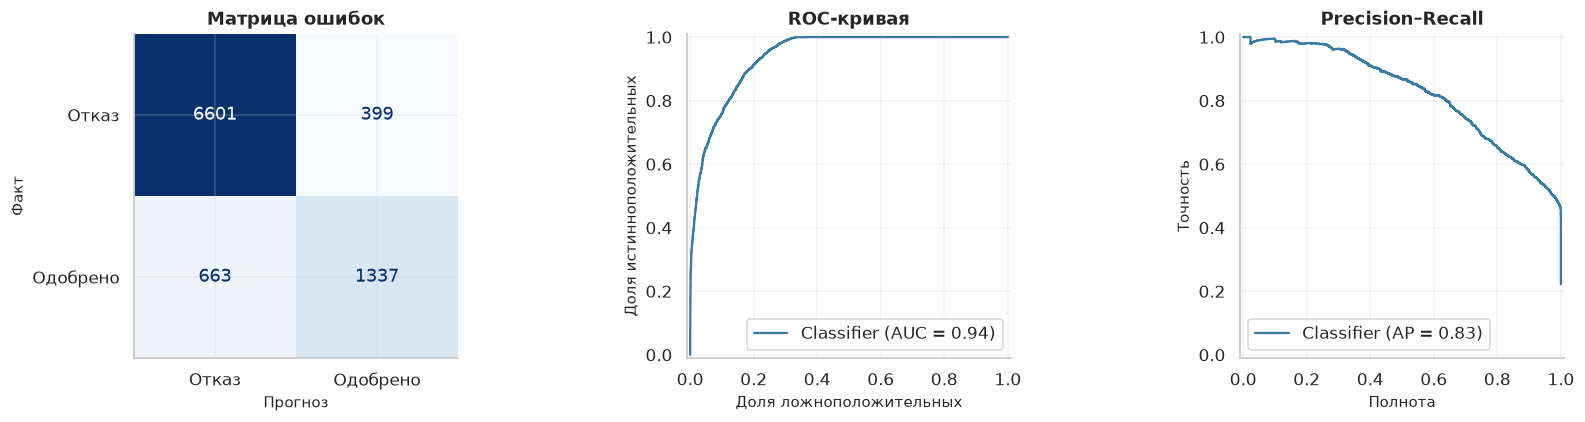

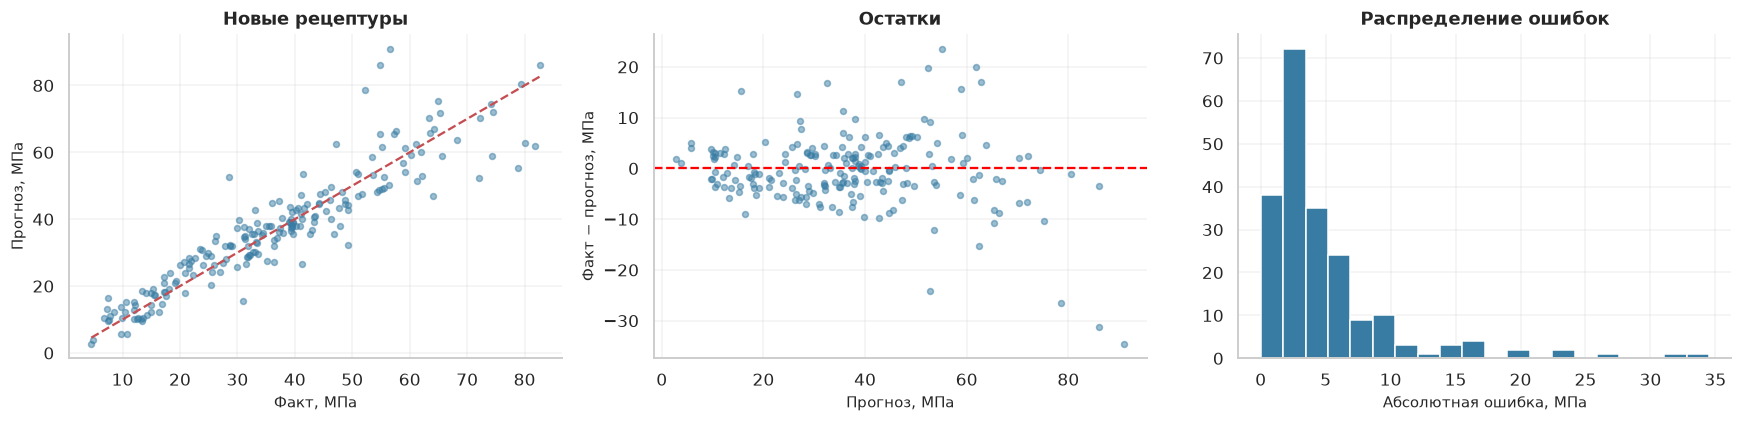

In [12]:
# Визуальная диагностика после выбора конфигурации; test не участвует в дальнейшем подборе.
y_c = tasks["classification"]["y_test"]
pred_c, prob_c = predictions["classification", "sklearn_improved"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_c, pred_c, ax=axes[0], colorbar=False, cmap="Blues", display_labels=["Отказ", "Одобрено"])
RocCurveDisplay.from_predictions(y_c, prob_c, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_c, prob_c, ax=axes[2])
axes[0].set(title="Матрица ошибок", xlabel="Прогноз", ylabel="Факт")
axes[1].set(title="ROC-кривая", xlabel="Доля ложноположительных", ylabel="Доля истинноположительных")
axes[2].set(title="Precision–Recall", xlabel="Полнота", ylabel="Точность")
plt.tight_layout()
plt.show()
y_r = tasks["regression"]["y_test"].to_numpy()
pred_r = predictions["regression", "sklearn_improved"][0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(y_r, pred_r, alpha=.5, s=15)
axes[0].plot([y_r.min(), y_r.max()], [y_r.min(), y_r.max()], "r--")
axes[0].set(xlabel="Факт, МПа", ylabel="Прогноз, МПа", title="Новые рецептуры")
axes[1].scatter(pred_r, y_r - pred_r, alpha=.5, s=15)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Прогноз, МПа", ylabel="Факт − прогноз, МПа", title="Остатки")
axes[2].hist(np.abs(y_r - pred_r), bins=20)
axes[2].set(xlabel="Абсолютная ошибка, МПа", title="Распределение ошибок")
plt.tight_layout()
plt.show()

### Что видно по ошибкам

У улучшенного классификатора precision составляет **77,02%**, а recall — **66,85%**. То есть среди предсказанных одобрений большинство верны, но модель находит не все заявки класса 1: остаётся примерно 33,15% пропущенных одобрений. Поэтому одного роста accuracy было бы недостаточно для оценки результата.

В регрессии MAE равна **4,870 МПа**, а RMSE — **7,140 МПа**. Разница между ними показывает, что наряду с небольшими ошибками остаются и более крупные промахи. По графику остатков можно увидеть их отдельно от средней метрики.

### Сходится ли своя модель

Проверю, насколько отличаются ответы своей реализации и sklearn.
Для логистической регрессии также посмотрю на убывание функции потерь
и норму градиента в конце обучения. Это поможет убедиться,
что близкие метрики получились после нормального завершения оптимизации.

classification baseline {'different_class_fraction': 0.0, 'max_probability_difference': 4.440892098500626e-16}
classification improved {'different_class_fraction': 0.0, 'max_probability_difference': 3.552713678800501e-15}
regression baseline {'mean_absolute_prediction_difference': 1.803950732051128e-14, 'max_absolute_prediction_difference': 7.105427357601002e-14}
regression improved {'mean_absolute_prediction_difference': 4.956552967413903e-14, 'max_absolute_prediction_difference': 6.110667527536862e-13}


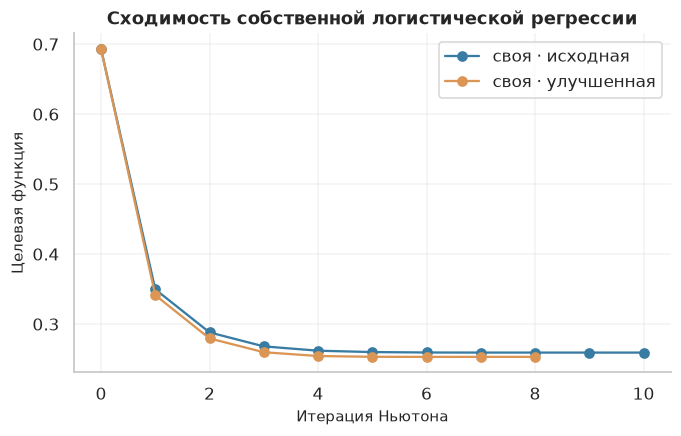

Модель,Итерации,Норма градиента,Функция потерь
своя · исходная,11,4.63e-11,0.259218
своя · улучшенная,9,3.00e-10,0.253066


In [13]:
# При равных целях оптимизации ожидается близость прогнозов, а не обязательное равенство битов.
agreements = {}
for task in tasks:
    agreements[task] = {}
    for stage in ["baseline", "improved"]:
        own, own_prob = predictions[task, "custom_" + stage]
        ref, ref_prob = predictions[task, "sklearn_" + stage]
        if task == "classification":
            difference = {"different_class_fraction": float(np.mean(own != ref)),
                          "max_probability_difference": float(np.max(np.abs(own_prob - ref_prob)))}
            assert difference["max_probability_difference"] < 1e-5
        else:
            difference = {"mean_absolute_prediction_difference": float(np.mean(np.abs(own - ref))),
                          "max_absolute_prediction_difference": float(np.max(np.abs(own - ref)))}
            assert difference["max_absolute_prediction_difference"] < 1e-5
        agreements[task][stage] = difference
        print(task, stage, difference)
(RESULTS / "agreement.json").write_text(json.dumps(agreements, indent=2))
fig, ax = plt.subplots(figsize=(7, 4))
for item in convergence:
    ax.plot(range(len(item["loss_history"])), item["loss_history"], marker="o", label=MODEL_NAMES[item["model"]])
ax.set(xlabel="Итерация Ньютона", ylabel="Целевая функция", title="Сходимость собственной логистической регрессии")
ax.legend()
plt.show()
show_table(pd.DataFrame(convergence).drop(columns="loss_history"))

## 5. Сравнение результатов

Сравню улучшенные модели с исходными, а свою реализацию — со sklearn
до и после переноса улучшений. Для F1 положительная разность означает рост качества,
для MAE — увеличение ошибки.

В конце сопоставлю улучшенные модели этой работы с KNN из первой лабораторной.

In [14]:
# Сравню варианты внутри работы, затем добавлю улучшенный KNN для ориентира.
comparison_rows, knn_rows = [], []
pairs = [("sklearn_improved", "sklearn_baseline", "Улучшение sklearn"),
         ("custom_baseline", "sklearn_baseline", "Своя и sklearn: исходные"),
         ("custom_improved", "sklearn_improved", "Своя и sklearn: улучшенные"),
         ("custom_improved", "custom_baseline", "Улучшение своей модели")]
knn = pd.read_csv(ROOT / "lab_1" / "results" / "metrics.csv")
for task in tasks:
    m = metrics[metrics.task == task].set_index("model")
    metric = "f1" if task == "classification" else "mae"
    for left, right, label in pairs:
        comparison_rows.append({"Задача": TASK_NAMES[task], "Сравнение": label,
                                "Метрика": "F1" if metric == "f1" else "MAE, МПа",
                                "Разность": m.loc[left, metric] - m.loc[right, metric]})
    reference = knn[(knn.task == task) & (knn.model == "sklearn_improved")].iloc[0]
    assert reference.split_sha == tasks[task]["split_sha"]
    knn_rows.append({"Задача": TASK_NAMES[task], "Метрика": "F1" if metric == "f1" else "MAE, МПа",
                     "KNN": reference[metric], "Регрессия": m.loc["sklearn_improved", metric]})
show_table(pd.DataFrame(comparison_rows), "Изменение основных метрик")
show_table(pd.DataFrame(knn_rows), "Сравнение улучшенных моделей sklearn с первой работой")
show_table(metrics[["task", "model", "fit_seconds", "predict_seconds"]].reset_index(drop=True), "Время работы моделей")

Задача,Сравнение,Метрика,Разность
Классификация,Улучшение sklearn,F1,0.0228
Классификация,Своя и sklearn: исходные,F1,0.0000
Классификация,Своя и sklearn: улучшенные,F1,0.0000
Классификация,Улучшение своей модели,F1,0.0228
Регрессия,Улучшение sklearn,"MAE, МПа",-3.8076
Регрессия,Своя и sklearn: исходные,"MAE, МПа",0.0000
Регрессия,Своя и sklearn: улучшенные,"MAE, МПа",-0.0000
Регрессия,Улучшение своей модели,"MAE, МПа",-3.8076


Задача,Метрика,KNN,Регрессия
Классификация,F1,0.6960,0.7157
Регрессия,"MAE, МПа",4.4187,4.8704


Задача,Модель,"Обучение, с","Прогноз, с"
Классификация,Dummy,0.0462,0.0096
Классификация,sklearn · исходная,0.0796,0.0106
Классификация,sklearn · улучшенная,0.1778,0.0170
Классификация,своя · исходная,0.0968,0.0106
Классификация,своя · улучшенная,0.2191,0.0169
Регрессия,Dummy,0.0034,0.0013
Регрессия,sklearn · исходная,0.0034,0.0013
Регрессия,sklearn · улучшенная,0.0071,0.0024
Регрессия,своя · исходная,0.0031,0.0013
Регрессия,своя · улучшенная,0.0063,0.0024


### Итоговые показатели

Сохраню выбранные параметры и выведу основные метрики.
В регрессии улучшенная линейная модель может использовать Ridge:
это тот же линейный прогноз с дополнительным штрафом на коэффициенты.

Модель,F1 ↑,Precision,Recall
sklearn · исходная,0.6929,0.7355,0.6550
sklearn · улучшенная,0.7157,0.7702,0.6685
своя · исходная,0.6929,0.7355,0.6550
своя · улучшенная,0.7157,0.7702,0.6685


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
sklearn · исходная,8.6781,10.7918,0.6391
sklearn · улучшенная,4.8704,7.1397,0.8420
своя · исходная,8.6781,10.7918,0.6391
своя · улучшенная,4.8704,7.1397,0.8420


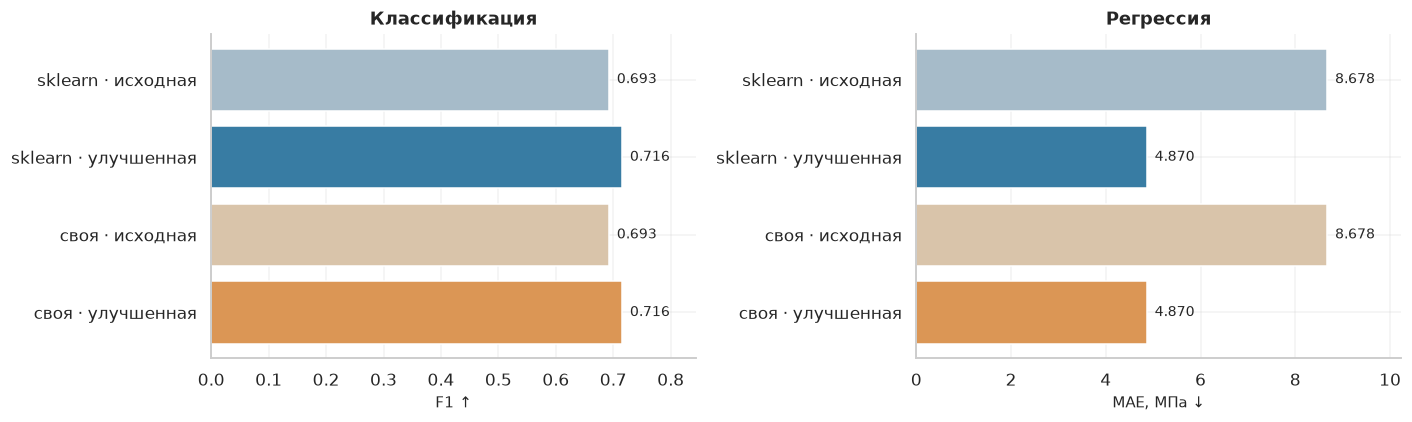

In [15]:
# Протокол содержит достаточно информации, чтобы проверить сопоставимость с лабораторной №1.
protocol = {"lab": 2, "seed": SEED, "cv_folds": 3, "selected": selected,
            "selection": "joint full-train CV of representations and hyperparameters; test reporting only",
            "classification_threshold": 0.5, "datasets": {},
            "versions": {"python": platform.python_version(), "numpy": np.__version__,
                         "pandas": pd.__version__, "sklearn": sklearn.__version__}}
reference = json.loads((ROOT / "lab_1" / "results" / "protocol.json").read_text())
for task, t in tasks.items():
    protocol["datasets"][task] = reference["datasets"][task]
(RESULTS / "protocol.json").write_text(json.dumps(protocol, ensure_ascii=False, indent=2))
for task in tasks:
    columns = ["model", "f1", "precision", "recall"] if task == "classification" else ["model", "mae", "rmse", "r2"]
    show_table(metrics.loc[(metrics.task == task) & (metrics.stage != "dummy"), columns].reset_index(drop=True), TASK_NAMES[task])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task, metric in zip(axes, ["classification", "regression"], ["f1", "mae"]):
    group = metrics[(metrics.task == task) & (metrics.stage != "dummy")]
    bars = ax.barh([MODEL_NAMES[name] for name in group.model], group[metric],
                   color=["#a6bbc9", "#387ca3", "#d9c4aa", "#db9655"])
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9)
    ax.set(title=TASK_NAMES[task], xlabel="F1 ↑" if metric == "f1" else "MAE, МПа ↓")
    ax.set_xlim(0, group[metric].max() * 1.18)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Выводы

Логарифмирование оказалось полезным в обеих задачах. Добавление отношений признаков
само по себе не дало улучшения среднего качества, а квадраты и взаимодействия помогли.
Поэтому в обеих задачах выбрано полиномиальное представление второй степени.

В классификации лучший вариант использует **C=0,1 и обычные веса классов**.
F1 на test вырос с **0,69294 до 0,71574**. Совместный подбор параметров дал лишь небольшой
дополнительный выигрыш по CV, поэтому основную роль здесь сыграли преобразования признаков.

В регрессии выбран **Ridge с alpha=1**. MAE снизилась с **8,678 до 4,870 МПа**,
то есть примерно на **43,9%**. Значит, исходной линейной зависимости для этих данных
не хватало, а нелинейные признаки вместе с регуляризацией заметно помогли.

Собственные реализации дали те же классы и практически те же численные прогнозы,
что и sklearn. Метод Ньютона сошёлся в обоих вариантах;
оставшиеся различия находятся на уровне вычислительной точности.

По сравнению с улучшенным KNN логистическая регрессия получила больший F1
(**0,71574 против 0,69597**), а KNN точнее предсказал прочность
(**MAE 4,419 против 4,870 МПа**). На этих задачах одного лучшего алгоритма не получилось.

Результаты относятся к одному test и выбранным данным. Для более устойчивого сравнения
стоило бы повторить эксперимент на других разбиениях, сохранив группировку рецептур бетона.

**Источники:** [данные](../lab_1/data/README.md),
[линейные модели в sklearn](https://scikit-learn.org/stable/modules/linear_model.html),
[LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

В исходных вариантах своя модель и sklearn совпали по F1 и по MAE.
Перенос полиномов и регуляризации повысил качество своей модели настолько же,
насколько и библиотечной. Поэтому разница со sklearn не объясняет выигрыш:
результат изменился за счёт признаков и выбранных параметров.

### Повторный запуск

Результаты сохранены в notebook и доступны без выполнения кода.
Для повторения использую Python 3.12; версии библиотек выведены в начале.
Нужны два исходных файла из `lab_1/data/raw`, сохранённые разбиения
`lab_1/results/split_classification.csv`, `split_regression.csv` и их `protocol.json`.
Открываю notebook из корня или папки `lab_2` и выполняю **Run All**.
Весь код чтения, преобразований, метрик и собственных моделей находится ниже соответствующих пояснений.
